# Supplemental Figure 5, Panel F

Lineplots showing gain of accessibility at IFNg- and Dex-inducible cREs. Represented either as one group or divided into early induced (1h), late induced (6h) or induced at both timepoints

*Output: PanelF.pdf*

# Setup

In [12]:
#load packages
library(tidyverse)
library(edgeR)
library(ggrastr)
library(gridExtra)
library(RColorBrewer)
library(patchwork)
library(pheatmap)
library(rtracklayer)
library(GenomicRanges)
library(here)
here::i_am("figures/SuppFig5/PanelF/PanelF.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))

sessionInfo()
here()

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] here_1.0.2           rtracklayer_1.58.0   GenomicRanges_1.50.2
 [4] GenomeInfoDb_1.34.9  IRanges_2.32.0       S4Vectors_0.36.2    
 [7] BiocGenerics_0.44.0  pheatmap_1.0.12      patchwork_1.3.0     
[10] RColorBrewer_1.1-3   gridExtra_2.3        ggrastr_1.0.2       
[13] edg

[1] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics"

# Load data

In [13]:
# Differential accessibility analysis results
dar_IFN_1h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_IFN_1h.tsv"),
  sep = "\t"
)

dar_IFN_6h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_IFN_6h.tsv"),
  sep = "\t"
)

dar_Dex_1h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_Dex_1h.tsv"),
  sep = "\t"
)

dar_Dex_6h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_Dex_6h.tsv"),
  sep = "\t"
)

# read in counts data
countmat_1h <- read.delim(
  here("inputs", "countmat", "GM12878_stimulus", "GM_stim_1h_counts_1.tsv"),
  header = FALSE,
  sep = "\t"
)

countmat_6h <- read.delim(
  here("inputs", "countmat", "GM12878_stimulus", "GM_stim_6h_counts_1.tsv"),
  header = FALSE,
  sep = "\t"
)

# read in row metadata
row_meta <- read.delim(
  here("inputs", "bed", "ATAC_peaks", "filtered", "consensus_filt_annot.tsv"),
  sep = "\t"
)

# read in column metadata
col_meta_1h <- read.delim(
  here("inputs", "countmat", "GM12878_stimulus", "metadata.txt"),
  sep = "\t"
)
col_meta_6h <- col_meta_1h

#filter to only include counts (exclude genomic coordinates)
counts_1h <- countmat_1h[,5:16]
counts_6h <- countmat_6h[,5:16]



# Scale and vehicle-normalize accessibility values

In [3]:
#convert to CPM
cpm_1h <- apply(counts_1h, 2, FUN=function(x) 1000000*x/sum(x)) 
cpm_6h <- apply(counts_6h, 2, FUN=function(x) 1000000*x/sum(x)) 

# average over replicates, Z-score by row, and normalize to vehicle
cpm_ifn <- data.frame(
    veh=rowMeans(cbind(cpm_1h[,1:2], cpm_6h[,1:2])),
    ifn_1h = rowMeans(cpm_1h[,3:4]),
    ifn_6h = rowMeans(cpm_6h[,3:4]))

cpm_ifn_scale <- apply(log2(cpm_ifn+1), 1, scale) %>% t() %>% data.frame() %>% `colnames<-`(colnames(cpm_ifn))

cpm_ifn_scale_vehNorm <- apply(cpm_ifn_scale, 2, FUN=function(x){x - cpm_ifn_scale$veh})

cpm_dex <- data.frame(
    veh=rowMeans(cbind(cpm_1h[,1:2], cpm_6h[,1:2])),
    dex_1h = rowMeans(cpm_1h[,5:6]),
    dex_6h = rowMeans(cpm_6h[,5:6]))

cpm_dex_scale <- apply(log2(cpm_dex+1), 1, scale) %>% t() %>% data.frame() %>% `colnames<-`(colnames(cpm_dex))

cpm_dex_scale_vehNorm <- apply(cpm_dex_scale, 2, FUN=function(x){x - cpm_dex_scale$veh})

# Generate plots - all inducible elements

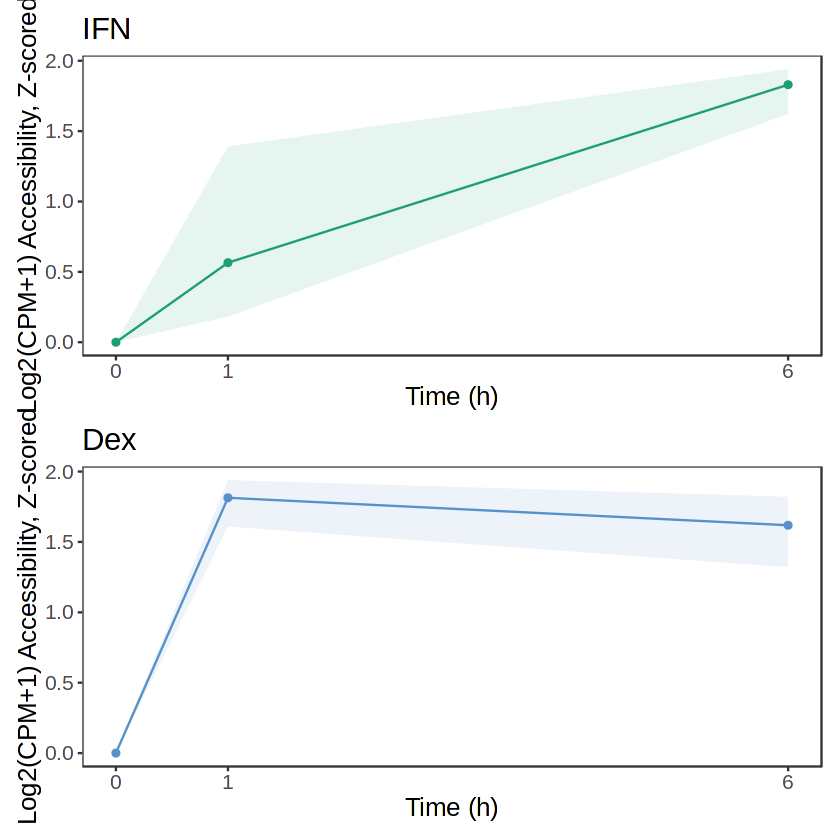

In [4]:

ifn_up_both <- (dar_IFN_1h$change == "up" & dar_IFN_6h$change == "up")
ifn_up_1h <- (dar_IFN_1h$change == "up" & dar_IFN_6h$change != "up")
ifn_up_6h <-  (dar_IFN_1h$change != "up" & dar_IFN_6h$change == "up")

dex_cols <- c("#5791c9", "#4777a6", "#345a7f")
ifn_cols <- c("#1c9e77", "#127555", "#0b4f3a")

p1 <- cpm_ifn_scale_vehNorm %>% 
    data.frame() %>% 
    mutate(category=case_when(ifn_up_both ~ "both", ifn_up_1h ~ "1h", ifn_up_6h ~ "6h", TRUE ~ "non_ind")) %>%
    filter(category != "non_ind") %>% 
    pivot_longer(!category) %>%
    mutate(time=case_when(grepl("veh", name) ~ 0, grepl("1h", name) ~ 1, grepl("6h",name)~6)) %>%
    group_by(time) %>%
    # calculate median and IQR (25th, 75th pctile) normalized accessibility values for each timepoint and condition
    summarize(median=median(value),
              pct_25=quantile(value,0.25),
              pct_75=quantile(value,0.75)) %>%
    ggplot(aes(x=time)) +
        geom_ribbon(aes(ymin=pct_25,ymax=pct_75), alpha=.1, linewidth=NA,  fill=ifn_cols[1]) +
        geom_line(aes(y=median), color=ifn_cols[1]) +
        geom_point(aes(y=median), color=ifn_cols[1]) +
    ggtitle("IFN") +
    xlab("Time (h)") + ylab("Log2(CPM+1) Accessibility, Z-scored") + scale_x_continuous(breaks=c(0,1,6))

dex_up_both <- (dar_Dex_1h$change == "up" & dar_Dex_6h$change == "up")
dex_up_1h <- (dar_Dex_1h$change == "up" & dar_Dex_6h$change != "up")
dex_up_6h <-  (dar_Dex_1h$change != "up" & dar_Dex_6h$change == "up")

p2 <- cpm_dex_scale_vehNorm %>% 
    data.frame() %>% 
    mutate(category=case_when(dex_up_both ~ "both", dex_up_1h ~ "1h", dex_up_6h ~ "6h", TRUE ~ "non_ind")) %>%
    filter(category != "non_ind") %>% 
    pivot_longer(!category) %>%
    mutate(time=case_when(grepl("veh", name) ~ 0, grepl("1h", name) ~ 1, grepl("6h",name)~6)) %>%
    group_by(time) %>%
    summarize(median=median(value),
              pct_25=quantile(value,0.25),
              pct_75=quantile(value,0.75)) %>%
    ggplot(aes(x=time)) +
        geom_ribbon(aes(ymin=pct_25,ymax=pct_75), alpha=.1, linewidth=NA, fill=dex_cols[1]) +
        geom_line(aes(y=median), color=dex_cols[1]) +
        geom_point(aes(y=median), color=dex_cols[1]) + 
    ggtitle("Dex") +
    xlab("Time (h)") + ylab("Log2(CPM+1) Accessibility, Z-scored") + scale_x_continuous(breaks=c(0,1,6))

p1 / p2

# Generate plots, separated by induction timepoint - early (1h), late (6h), or both 

In [5]:
p3 <- cpm_ifn_scale_vehNorm %>% 
    data.frame() %>% 
    mutate(category=case_when(ifn_up_both ~ "both", ifn_up_1h ~ "1h", ifn_up_6h ~ "6h", TRUE ~ "non_ind")) %>%
    filter(category != "non_ind") %>% 
    pivot_longer(!category) %>%
    mutate(time=case_when(grepl("veh", name) ~ 0, grepl("1h", name) ~ 1, grepl("6h",name)~6)) %>%
    group_by(category,time) %>%
    summarize(median=median(value),
              pct_25=quantile(value,0.25),
              pct_75=quantile(value,0.75)) %>%
    ggplot(aes(x=time, color=category)) +
        geom_ribbon(aes(ymin=pct_25,ymax=pct_75, fill=category), alpha=.1, linewidth=NA) +
        geom_line(aes(y=median)) +
        geom_point(aes(y=median)) +
    ggtitle("IFN") +
    xlab("Time (h)") + ylab("Log2(CPM+1) Accessibility, Z-scored") + scale_x_continuous(breaks=c(0,1,6)) +
    scale_color_manual(values=ifn_cols) + scale_fill_manual(values=ifn_cols) 

p4 <- cpm_dex_scale_vehNorm %>% 
    data.frame() %>% 
    mutate(category=case_when(dex_up_both ~ "both", dex_up_1h ~ "1h", dex_up_6h ~ "6h", TRUE ~ "non_ind")) %>%
    filter(category != "non_ind") %>% 
    pivot_longer(!category) %>%
    mutate(time=case_when(grepl("veh", name) ~ 0, grepl("1h", name) ~ 1, grepl("6h",name)~6)) %>%
    group_by(category,time) %>%
    summarize(median=median(value),
              pct_25=quantile(value,0.25),
              pct_75=quantile(value,0.75)) %>%
    ggplot(aes(x=time, color=category)) +
        geom_ribbon(aes(ymin=pct_25,ymax=pct_75, fill=category), alpha=.1, linewidth=NA) +
        geom_line(aes(y=median)) +
        geom_point(aes(y=median)) + 
    ggtitle("Dex") +
    xlab("Time (h)") + ylab("Log2(CPM+1) Accessibility, Z-scored") + scale_x_continuous(breaks=c(0,1,6)) +
    scale_color_manual(values=dex_cols) + scale_fill_manual(values=dex_cols) 


`summarise()` has grouped output by 'category'. You can override using the
`.groups` argument.
`summarise()` has grouped output by 'category'. You can override using the
`.groups` argument.


# Assemble figure panel

Saving 7 x 7 in image


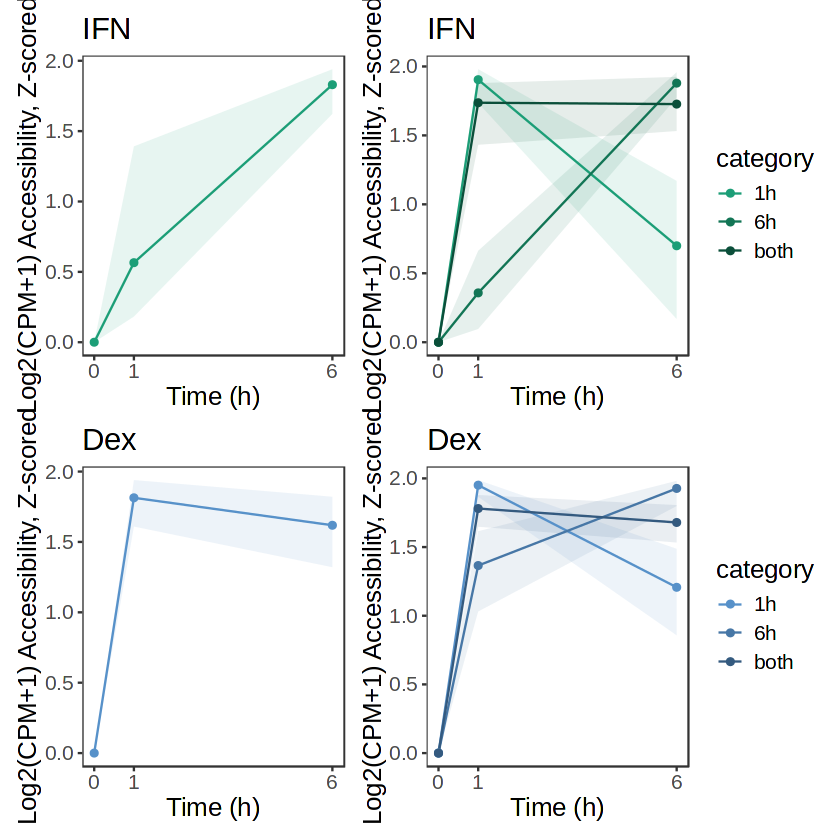

In [6]:
p1 + p3 + p2 + p4 + plot_layout(ncol=2)
ggsave("PanelF.pdf")